## Plot 2D slices of the density and velocity distribution

In [15]:
import numpy as np
import matplotlib.pyplot as plt
import os
import astropy.units as u
import json

import matplotlib.colors as mcolors
import matplotlib.cm as cm
from mpl_toolkits.axes_grid1 import make_axes_locatable

from transform_data import get_transformed_data
from field_config import field_cmaps, field_lims, field_labels, shck_color_list, shck_tick_num, shck_ticks, field_scales

import flash_amr_tools
import h5py

In [16]:
fig_dir = "/home/kwatanabe/Projects/cr-bowshocks/figures/crmhd_vs_mhd"
flash_output_dir = "/home/kwatanabe/Projects/cr-bowshocks/outputs_new"

# load the bowshock config
bowshock_config = json.load(open("../config/bowshock_config.json", "r"))["config"]

In [17]:
sims = ["ISM-v30-MHD", "ISM-v30"]
# sim_label = ["ISM-v30-MHD", "ISM-v30-CRMHD"]
fields = ["dens", "vel", "temp", "pres", "mag"]

sim_textlabel = {
    "ISM-v30" : (15, -21),
    "ISM-v30-MHD" : (8, -21)
}

minimum position of the region of interest:  [-7.71419395e+19 -7.71419395e+19 -7.71419395e+19]
maximum position of the region of interest:  [2.31425819e+20 7.71419395e+19 7.71419395e+19]
Finding all leaf blocks in given region
46412 46412
Biggest block has refinement level: 4
Highest refinement level in simulation: 7
Highest refinement level in selected box: 7
Extending region to fit amr structure at level 4.
Trying extended region given by including blocks whose center is not in predefined region but part of their block volume is.
bnx, bny, bnz:  16.0 8.0 8.0
Block shape:  (16, 8, 8)
Total number of blocks including parent blocks: 52896
Region extended to:	lower		upper
	x	-7.71419381e+19		+2.31425806e+20
	y	-7.71419381e+19		+7.71419381e+19
	z	-7.71419381e+19		+7.71419381e+19

Region center at:	+7.71419293e+19	+0.00000000e+00	+0.00000000e+00
Given center:		+7.71419398e+19	+0.00000000e+00	+0.00000000e+00
minimum position of the region of interest:  [-7.71419395e+19 -7.71419395e+19 -7.71

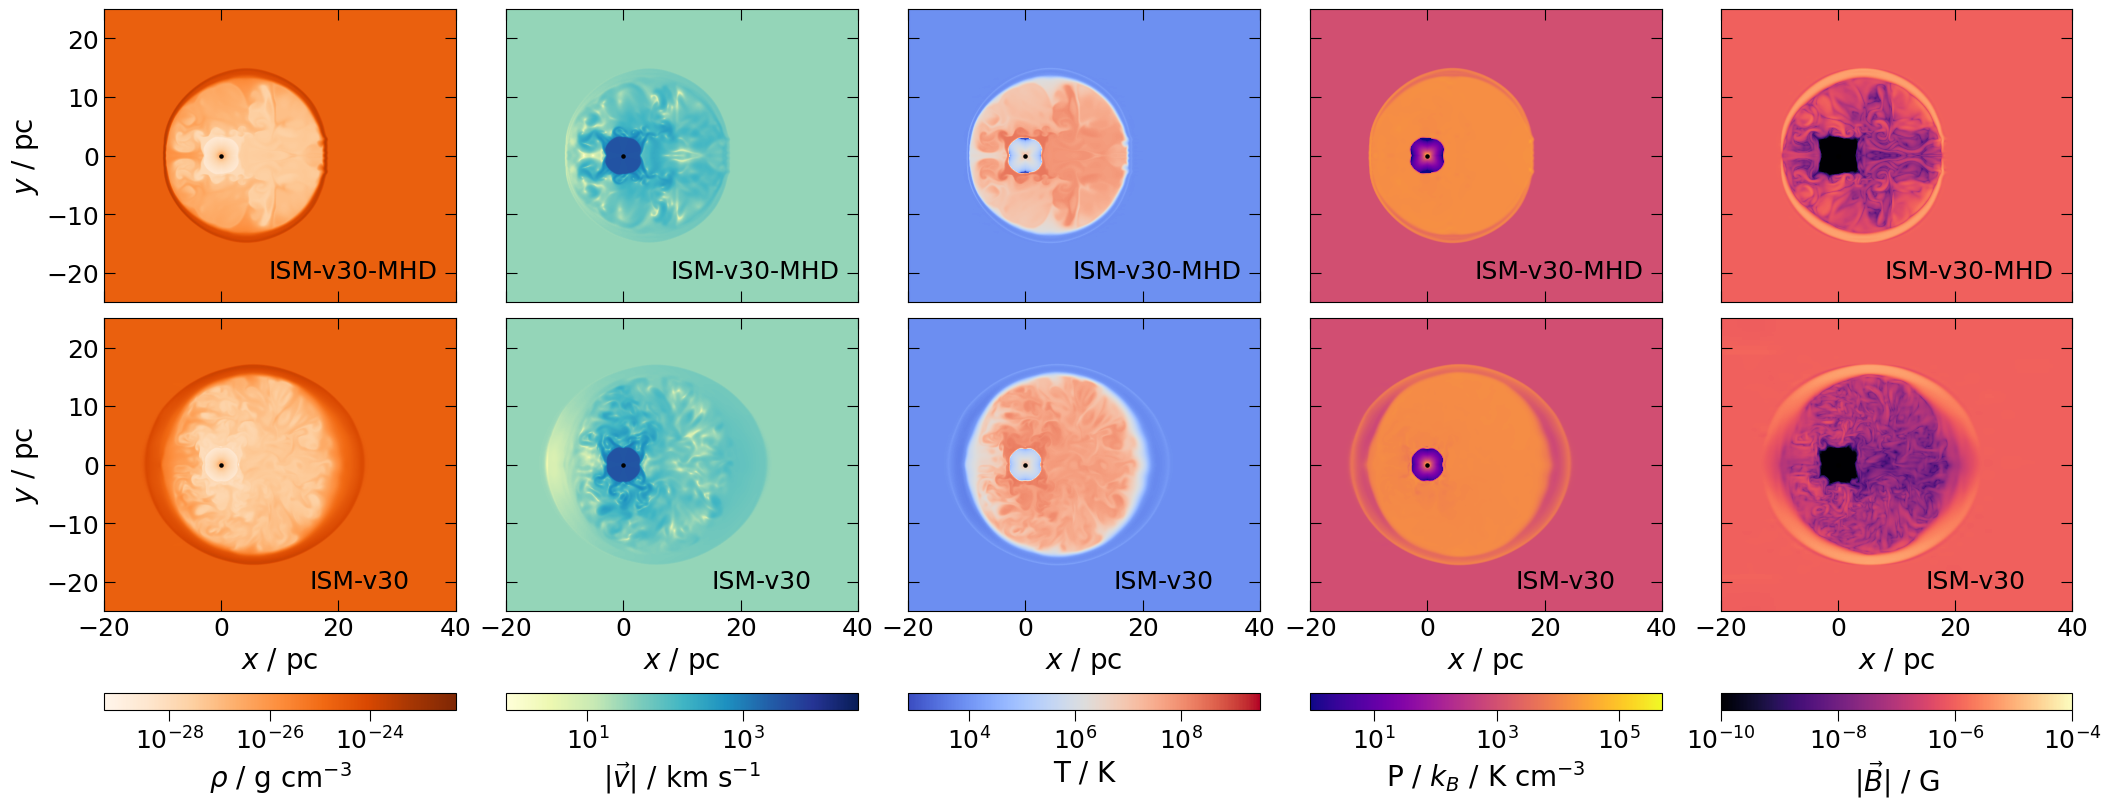

In [21]:
fig = plt.figure(figsize=(21, 8), constrained_layout=True)
gs = fig.add_gridspec(len(sims), len(fields), hspace=0, wspace=0)
axs = gs.subplots(sharex=True, sharey=True)

for isim, sim in enumerate(sims):
    sim_dir = os.path.join(flash_output_dir, bowshock_config[sim]["sim_dir"])

    sim_file = os.path.join(sim_dir, "starISM_hdf5_plt_cnt_0020")
    
    blist, brefs, bns = flash_amr_tools.get_true_blocks(sim_file)

    pf = h5py.File(sim_file)
    ref_lvl = pf["refine level"][()][blist]
    bbox = pf["bounding box"][()][blist]
    bsize = pf["block size"][()][blist]

    low_cor, up_cor = bbox[0,:,0], bbox[-1,:,1]

    # extent for imshow
    extent = ([low_cor[0], up_cor[0], low_cor[1], up_cor[1]] * u.cm).to_value(u.pc)

    for ifield, field in enumerate(fields):
        field_data = get_transformed_data(pf, field, blist)
        field_slice = flash_amr_tools.get_slice(field_data, pos=0.0, axis=2, ref_lvl=ref_lvl, bbox=bbox, bsize=bsize, brefs=brefs, bns=bns)

        # normaliztion for color
        if field == "shck":
            # define bins and normalize
            bounds = np.array([1, 3, 5, 7]) - 1
            norm = mcolors.BoundaryNorm(bounds, len(shck_color_list))
        elif field in ("shma", "mach", "crac", "mgob"):
            norm = mcolors.Normalize(vmin=field_lims[field][0], vmax=field_lims[field][1], clip=True)
        else:
            norm = mcolors.LogNorm(vmin=field_lims[field][0], vmax=field_lims[field][1], clip=True)

        im = axs[isim, ifield].imshow(field_slice.T, norm=norm, cmap=field_cmaps[field], origin="lower", extent=extent)
        axs[isim, ifield].scatter(0, 0, s=5.0, color="k")

        # labels
        if isim == len(sims) -1:
            axs[isim, ifield].set_xlabel("$x$ / pc", fontsize=20)
        # if isim == 0:
        if ifield == 0 :
            axs[isim, ifield].set_ylabel("$y$ / pc", fontsize=20)
        # ticks
        axs[isim, ifield].tick_params(axis='both', direction="in", which='major', size=8, labelsize=18, top=True, right=True)
        axs[isim, ifield].tick_params(axis='both', direction="in", which='minor', size=6, labelsize=16, top=True, right=True)

        axs[isim, ifield].set_xlim(-20, 40)
        axs[isim, ifield].set_ylim(-25,25)

        # add annotations for the simulation labels
        axs[isim,ifield].annotate(sim, xy=sim_textlabel[sim], color="k", fontsize=18)

        if isim == len(sims) -1:
        # colorbar
        # make separate axes for each image
        # divider = make_axes_locatable(axs[isim,ifield])
        # cax = divider.append_axes("bottom", size="5%", pad=1.0)
            sm = cm.ScalarMappable(cmap=field_cmaps[field], norm=norm)

            # set ticks as text for shck
            if field == "shck":
                cb = fig.colorbar(sm, ax=axs[isim,ifield], ticks=shck_tick_num, orientation="horizontal")
                cb.ax.set_xticklabels(shck_ticks, rotation=90)
                cb.ax.tick_params(axis='both', which='major', size=0, labelsize=14.5)
                cb.ax.tick_params(axis='both', which='minor', size=0)

            else:
                cb = fig.colorbar(sm, ax=axs[isim,ifield], orientation="horizontal")
                cb.ax.set_xlabel(field_labels[field], fontsize=20)
                cb.ax.tick_params(axis='both', which='major', size=8, labelsize=18)
                cb.ax.tick_params(axis='both', which='minor', size=6, labelsize=18)

                # scales
                cb.ax.set_xscale(field_scales[field])
            # cb.ax.tick_params(rotation=90)

        

    pf.close()

fig.savefig(f"{fig_dir}/2d_slices_t200.png", dpi=200, bbox_inches="tight")